In [681]:
from pathlib import Path
data_dir=Path(r"C:\Users\KISHAN PANWAR\Downloads\archive")
data_dir.glob("*.csv")


In [682]:
for files in data_dir.glob("*.csv"):
    print(files)

C:\Users\KISHAN PANWAR\Downloads\archive\olist_customers_dataset.csv
C:\Users\KISHAN PANWAR\Downloads\archive\olist_geolocation_dataset.csv
C:\Users\KISHAN PANWAR\Downloads\archive\olist_orders_dataset.csv
C:\Users\KISHAN PANWAR\Downloads\archive\olist_order_items_dataset.csv
C:\Users\KISHAN PANWAR\Downloads\archive\olist_order_payments_dataset.csv
C:\Users\KISHAN PANWAR\Downloads\archive\olist_order_reviews_dataset.csv
C:\Users\KISHAN PANWAR\Downloads\archive\olist_products_dataset.csv
C:\Users\KISHAN PANWAR\Downloads\archive\olist_sellers_dataset.csv
C:\Users\KISHAN PANWAR\Downloads\archive\product_category_name_translation.csv


In [683]:
import pandas as pd
orders_path=Path(r"C:\Users\KISHAN PANWAR\Downloads\archive\olist_orders_dataset.csv")
df=pd.read_csv(orders_path)
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [684]:
df.shape


(99441, 8)

In [685]:
df.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [686]:
df.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [687]:
df['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [688]:
df["order_id"].nunique()

99441

In [689]:
df.groupby("order_status")["order_delivered_customer_date"].apply(
    lambda x: x.isna().sum()
)

order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64

In [690]:
# Create a separate copy
orders = df.copy()

# Convert the actual delivery date
orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    errors="coerce"
)

# Convert the estimated delivery date
orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    errors="coerce"
)

In [691]:
orders[[
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]].dtypes

order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [692]:
orders[[
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]].isna().sum()

order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [693]:
print((df["order_status"]=="delivered") & (df["order_delivered_customer_date"].notna()))







0        True
1        True
2        True
3        True
4        True
         ... 
99436    True
99437    True
99438    True
99439    True
99440    True
Length: 99441, dtype: bool


In [694]:
eligible_mask = (
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna())
)

delivered_orders = orders[eligible_mask]

print(delivered_orders.shape)

(96470, 8)


In [695]:
delivered_orders["late_delivery"] = (
    delivered_orders["order_delivered_customer_date"] >
    delivered_orders["order_estimated_delivery_date"]
)

In [696]:
print(delivered_orders["late_delivery"].value_counts())

late_delivery
False    88644
True      7826
Name: count, dtype: int64


In [697]:
late_percentage = delivered_orders["late_delivery"].mean() * 100
print(f"Late delivery percentage: {late_percentage:.2f}%")

Late delivery percentage: 8.11%


In [698]:
import pandas as pd

delivered_orders = delivered_orders.copy()

# make sure both columns are real datetimes (the .dt accessor fails on strings)
for col in ["order_delivered_customer_date", "order_estimated_delivery_date"]:
    delivered_orders[col] = pd.to_datetime(delivered_orders[col])

delivered_orders["delay_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

print(delivered_orders["delay_days"].describe())

print(
    delivered_orders.groupby("late_delivery")["delay_days"]
    .agg(["count", "mean", "median", "min", "max"])
)

count    96470.000000
mean       -11.178126
std         10.184354
min       -146.016123
25%        -16.244065
50%        -11.948102
75%         -6.389815
max        188.975081
Name: delay_days, dtype: float64
               count       mean     median         min         max
late_delivery                                                     
False          88644 -13.008280 -12.317789 -146.016123   -0.000058
True            7826   9.551776   5.806481    0.002500  188.975081


In [699]:
late_orders = delivered_orders[
    delivered_orders["late_delivery"]
]

print(
    late_orders.nlargest(10, "delay_days")[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_estimated_delivery_date",
            "order_delivered_customer_date",
            "delay_days",
        ]
    ]
)

                               order_id order_purchase_timestamp  \
55619  1b3190b2dfa9d789e1f14c05b647a14a      2018-02-23 14:57:35   
19590  ca07593549f1816d26a572e06dc1eab6      2017-02-21 23:31:27   
11399  47b40429ed8cce3aee9199792275433f      2018-01-03 09:44:01   
81401  2fe324febf907e3ea3f2aa9650869fa5      2017-03-13 20:17:10   
89130  285ab9426d6982034523a855f55a885e      2017-03-08 22:47:40   
61610  440d0d17af552815d15a9e41abe49359      2017-03-07 23:59:51   
68769  c27815f7e3dd0b926b58552628481575      2017-03-15 23:23:17   
40847  d24e8541128cea179a11a65176e0a96f      2017-06-12 13:14:11   
38509  0f4519c5f1c541ddec9f21b3bddd533a      2017-03-09 13:26:57   
54480  2d7561026d542c8dbd8f0daeadf67a43      2017-03-15 11:24:27   

      order_estimated_delivery_date order_delivered_customer_date  delay_days  
55619                    2018-03-15           2018-09-19 23:24:07  188.975081  
19590                    2017-03-22           2017-09-19 14:36:39  181.608785  
11399      

In [700]:
# Check how many orders share the same actual delivery dates
print(
    late_orders["order_delivered_customer_date"]
    .dt.date
    .value_counts()
    .head(10)
)

order_delivered_customer_date
2018-04-03    99
2018-03-23    89
2018-03-29    88
2018-03-28    87
2018-04-10    87
2018-04-04    83
2018-04-11    76
2018-03-27    75
2018-04-05    74
2018-04-06    73
Name: count, dtype: int64


In [701]:
# Count orders sharing the same actual delivery date
delivery_date_counts = (
    late_orders["order_delivered_customer_date"]
    .dt.date
    .value_counts()
)

print(delivery_date_counts.head(10))

order_delivered_customer_date
2018-04-03    99
2018-03-23    89
2018-03-29    88
2018-03-28    87
2018-04-10    87
2018-04-04    83
2018-04-11    76
2018-03-27    75
2018-04-05    74
2018-04-06    73
Name: count, dtype: int64


In [702]:
# Inspect the most frequent delivery dates
print(
    delivery_date_counts[
        delivery_date_counts >= 5
    ]
)

order_delivered_customer_date
2018-04-03    99
2018-03-23    89
2018-03-29    88
2018-03-28    87
2018-04-10    87
              ..
2017-10-24     5
2017-06-22     5
2018-07-06     5
2017-09-13     5
2018-05-26     5
Name: count, Length: 343, dtype: int64


In [703]:
from pathlib import Path
import pandas as pd
import sqlite3

data_dir = Path(r"C:\Users\KISHAN PANWAR\Downloads\archive")

# Load the required datasets
orders = pd.read_csv(data_dir / "olist_orders_dataset.csv")
order_items = pd.read_csv(data_dir / "olist_order_items_dataset.csv")
products = pd.read_csv(data_dir / "olist_products_dataset.csv")
sellers = pd.read_csv(data_dir / "olist_sellers_dataset.csv")

print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Products:", products.shape)
print("Sellers:", sellers.shape)

Orders: (99441, 8)
Order items: (112650, 7)
Products: (32951, 9)
Sellers: (3095, 4)


In [704]:
import sqlite3

db_path = data_dir / "olist_project.db"
conn = sqlite3.connect(db_path)

orders.to_sql("orders", conn, if_exists="replace", index=False)
order_items.to_sql("order_items", conn, if_exists="replace", index=False)
products.to_sql("products", conn, if_exists="replace", index=False)
sellers.to_sql("sellers", conn, if_exists="replace", index=False)

print("SQLite database created successfully!")

SQLite database created successfully!


In [705]:
query = """
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
"""

pd.read_sql_query(query, conn)

,name
0,order_items
1,orders
2,products
3,reviews
4,sellers


In [706]:
query = """
SELECT
    order_status,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;
"""

pd.read_sql_query(query, conn)

,order_status,total_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [707]:
query = """
WITH delivery_labels AS (
    SELECT
        order_id,
        CASE
            WHEN order_delivered_customer_date
                 > order_estimated_delivery_date
            THEN 1
            ELSE 0
        END AS late_delivery
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
)
SELECT
    COUNT(*) AS eligible_orders,
    SUM(late_delivery) AS late_orders,
    ROUND(100.0 * AVG(late_delivery), 2) AS late_rate_pct
FROM delivery_labels;
"""

pd.read_sql_query(query, conn)

,eligible_orders,late_orders,late_rate_pct
0,96470,7826,8.11


In [708]:
query = """
WITH delivery_labels AS (
    SELECT
        order_id,
        CASE
            WHEN order_delivered_customer_date
                 > order_estimated_delivery_date
            THEN 1
            ELSE 0
        END AS late_delivery
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
),
order_category AS (
    SELECT DISTINCT
        oi.order_id,
        p.product_category_name
    FROM order_items oi
    JOIN products p
        ON oi.product_id = p.product_id
)
SELECT
    COALESCE(oc.product_category_name, 'unknown') AS category,
    COUNT(*) AS eligible_orders,
    SUM(dl.late_delivery) AS late_orders,
    ROUND(100.0 * AVG(dl.late_delivery), 2) AS late_rate_pct
FROM delivery_labels dl
JOIN order_category oc
    ON dl.order_id = oc.order_id
GROUP BY COALESCE(oc.product_category_name, 'unknown')
HAVING COUNT(*) >= 100
ORDER BY late_rate_pct DESC;
"""

category_results = pd.read_sql_query(query, conn)
category_results.head(15)

,category,eligible_orders,late_orders,late_rate_pct
0,audio,348,45,12.93
1,fashion_underwear_e_moda_praia,117,15,12.82
2,livros_tecnicos,256,28,10.94
3,casa_conforto,392,41,10.46
4,alimentos,441,44,9.98
5,eletronicos,2517,247,9.81
6,artigos_de_natal,125,12,9.60
7,bebes,2809,258,9.18
8,moveis_escritorio,1254,115,9.17
9,unknown,1392,127,9.12


In [709]:
query = """
WITH delivery_labels AS (
    SELECT
        order_id,
        order_purchase_timestamp,
        CASE
            WHEN order_delivered_customer_date
                 > order_estimated_delivery_date
            THEN 1
            ELSE 0
        END AS late_delivery
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
),
monthly_metrics AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COUNT(*) AS eligible_orders,
        SUM(late_delivery) AS late_orders,
        100.0 * AVG(late_delivery) AS late_rate_pct
    FROM delivery_labels
    GROUP BY strftime('%Y-%m', order_purchase_timestamp)
)
SELECT
    month,
    eligible_orders,
    late_orders,
    ROUND(late_rate_pct, 2) AS late_rate_pct,
    ROUND(
        100.0
        * SUM(late_orders) OVER (
            ORDER BY month
            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
        )
        / SUM(eligible_orders) OVER (
            ORDER BY month
            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
        ),
        2
    ) AS rolling_3_month_late_rate_pct
FROM monthly_metrics
ORDER BY month;
"""

monthly_results = pd.read_sql_query(query, conn)
monthly_results

,month,eligible_orders,late_orders,late_rate_pct,rolling_3_month_late_rate_pct
0,2016-09,1,1,100.00,100.00
1,2016-10,265,3,1.13,1.50
2,2016-12,1,0,0.00,1.50
3,2017-01,750,23,3.07,2.56
4,2017-02,1653,53,3.21,3.16
5,2017-03,2546,142,5.58,4.40
6,2017-04,2303,181,7.86,5.78
7,2017-05,3545,128,3.61,5.37
8,2017-06,3135,121,3.86,4.79
9,2017-07,3872,133,3.43,3.62


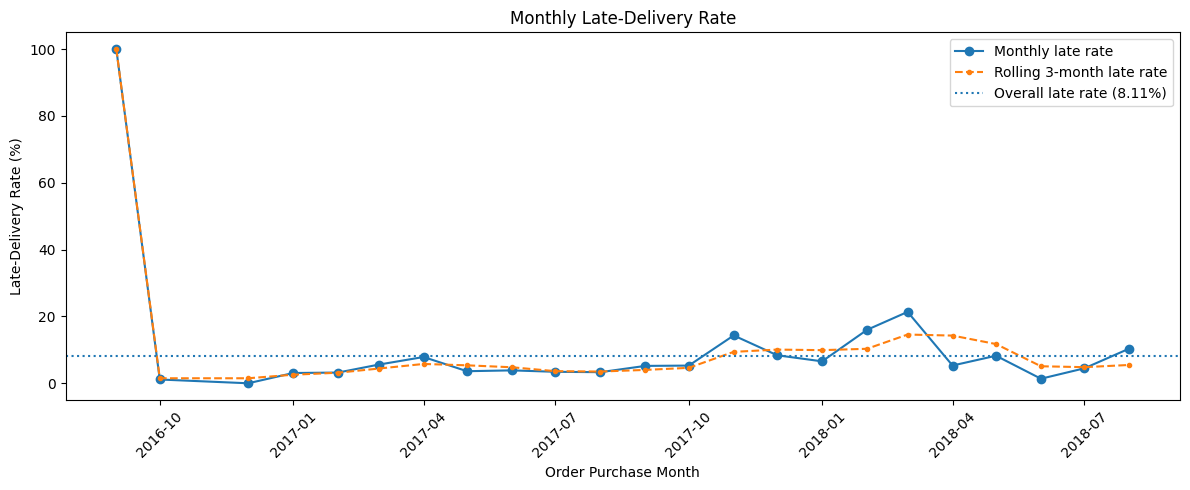

In [710]:
import matplotlib.pyplot as plt

plot_data = monthly_results.copy()
plot_data["month"] = pd.to_datetime(plot_data["month"])

plt.figure(figsize=(12, 5))

plt.plot(
    plot_data["month"],
    plot_data["late_rate_pct"],
    marker="o",
    label="Monthly late rate"
)

plt.plot(
    plot_data["month"],
    plot_data["rolling_3_month_late_rate_pct"],
    marker=".",
    linestyle="--",
    label="Rolling 3-month late rate"
)

plt.axhline(
    y=8.11,
    linestyle=":",
    label="Overall late rate (8.11%)"
)

plt.title("Monthly Late-Delivery Rate")
plt.xlabel("Order Purchase Month")
plt.ylabel("Late-Delivery Rate (%)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [711]:
reviews = pd.read_csv(
    data_dir / "olist_order_reviews_dataset.csv"
)

print("Reviews shape:", reviews.shape)
print(reviews.columns.tolist())
reviews.head()

Reviews shape: (99224, 7)
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [712]:
reviews.to_sql(
    "reviews",
    conn,
    if_exists="replace",
    index=False
)

query = """
WITH delivery_labels AS (
    SELECT
        order_id,
        CASE
            WHEN order_delivered_customer_date
                 > order_estimated_delivery_date
            THEN 1
            ELSE 0
        END AS late_delivery
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
)
SELECT
    dl.order_id,
    dl.late_delivery,
    r.review_score
FROM delivery_labels dl
JOIN reviews r
    ON dl.order_id = r.order_id
WHERE r.review_score IS NOT NULL;
"""

review_analysis = pd.read_sql_query(query, conn)

print("Joined rows:", review_analysis.shape)
print("Unique orders:", review_analysis["order_id"].nunique())
print("Duplicate order IDs:", review_analysis["order_id"].duplicated().sum())

print(
    review_analysis.groupby("late_delivery")["review_score"]
    .agg(["count", "mean", "median", "std"])
)

Joined rows: (96353, 3)
Unique orders: 95824
Duplicate order IDs: 529
               count      mean  median       std
late_delivery                                   
0              88653  4.293718     5.0  1.147755
1               7700  2.566494     2.0  1.658340


In [713]:
order_reviews = (
    review_analysis
    .groupby(["order_id", "late_delivery"], as_index=False)
    .agg(review_score=("review_score", "mean"))
)

print("Order-level rows:", len(order_reviews))
print("Unique orders:", order_reviews["order_id"].nunique())

print(
    order_reviews.groupby("late_delivery")["review_score"]
    .agg(["count", "mean", "median", "std"])
)

Order-level rows: 95824
Unique orders: 95824
               count      mean  median       std
late_delivery                                   
0              88163  4.294292     5.0  1.146029
1               7661  2.566506     2.0  1.657815


In [714]:
from scipy.stats import mannwhitneyu

on_time_scores = order_reviews.loc[
    order_reviews["late_delivery"] == 0,
    "review_score"
]

late_scores = order_reviews.loc[
    order_reviews["late_delivery"] == 1,
    "review_score"
]

result = mannwhitneyu(
    late_scores,
    on_time_scores,
    alternative="two-sided"
)

print(f"U statistic: {result.statistic:.2f}")
print(f"P-value: {result.pvalue:.3e}")

U statistic: 150680825.50
P-value: 0.000e+00


In [715]:
import numpy as np

late = late_scores.to_numpy()
on_time = on_time_scores.to_numpy()

# Probability of late score > on-time score
# minus probability of late score < on-time score
combined = np.concatenate([late, on_time])
ranks = pd.Series(combined).rank(method="average").to_numpy()

n_late = len(late)
n_on_time = len(on_time)

rank_sum_late = ranks[:n_late].sum()
u_late = rank_sum_late - n_late * (n_late + 1) / 2

cliffs_delta = (
    2 * u_late / (n_late * n_on_time)
) - 1

print(f"Cliff's delta: {cliffs_delta:.4f}")

Cliff's delta: -0.5538


In [716]:
import numpy as np

rng = np.random.default_rng(42)
n_bootstrap = 5000

late_array = late_scores.to_numpy()
on_time_array = on_time_scores.to_numpy()

bootstrap_differences = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    late_sample = rng.choice(
        late_array, size=len(late_array), replace=True
    )
    on_time_sample = rng.choice(
        on_time_array, size=len(on_time_array), replace=True
    )

    bootstrap_differences[i] = (
        late_sample.mean() - on_time_sample.mean()
    )

ci_lower, ci_upper = np.percentile(
    bootstrap_differences, [2.5, 97.5]
)

observed_difference = late_array.mean() - on_time_array.mean()

print(f"Mean difference (late - on-time): {observed_difference:.4f}")
print(f"95% bootstrap CI: [{ci_lower:.4f}, {ci_upper:.4f}]")

Mean difference (late - on-time): -1.7278
95% bootstrap CI: [-1.7668, -1.6899]


In [717]:

from pathlib import Path
import pandas as pd
import numpy as np

data_dir = Path(r"C:\Users\KISHAN PANWAR\Downloads\archive")

# 1. Load raw datasets into separate variables
orders_raw = pd.read_csv(data_dir / "olist_orders_dataset.csv")
items_raw = pd.read_csv(data_dir / "olist_order_items_dataset.csv")
products_raw = pd.read_csv(data_dir / "olist_products_dataset.csv")
customers_raw = pd.read_csv(data_dir / "olist_customers_dataset.csv")

# 2. Convert date columns to datetime
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders_raw[col] = pd.to_datetime(orders_raw[col], errors="coerce")

# 3. Keep orders with a known delivery outcome
eligible = orders_raw[
    (orders_raw["order_status"] == "delivered") &
    orders_raw["order_delivered_customer_date"].notna() &
    orders_raw["order_purchase_timestamp"].notna() &
    orders_raw["order_estimated_delivery_date"].notna()
].copy()

# 4. Create target variable
eligible["late_delivery"] = (
    eligible["order_delivered_customer_date"] >
    eligible["order_estimated_delivery_date"]
).astype(int)

# 5. Aggregate item-level data into order-level features
item_features = (
    items_raw.groupby("order_id")
    .agg(
        item_count=("order_item_id", "count"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        seller_count=("seller_id", "nunique")
    )
    .reset_index()
)

# 6. Find the most common product category in each order
item_categories = items_raw.merge(
    products_raw[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

item_categories["product_category_name"] = (
    item_categories["product_category_name"].fillna("unknown")
)

category_features = (
    item_categories.groupby(["order_id", "product_category_name"])
    .size()
    .reset_index(name="category_item_count")
    .sort_values(
        ["order_id", "category_item_count", "product_category_name"],
        ascending=[True, False, True]
    )
    .drop_duplicates("order_id")
    [["order_id", "product_category_name"]]
    .rename(columns={"product_category_name": "main_category"})
)

# 7. Add customer state
customer_features = customers_raw[
    ["customer_id", "customer_state"]
].drop_duplicates("customer_id")

# 8. Build the modelling dataset
model_df = eligible[
    [
        "order_id",
        "customer_id",
        "order_purchase_timestamp",
        "order_estimated_delivery_date",
        "late_delivery"
    ]
].copy()

model_df = model_df.merge(item_features, on="order_id", how="left")
model_df = model_df.merge(category_features, on="order_id", how="left")
model_df = model_df.merge(customer_features, on="customer_id", how="left")

# 9. Extract features available at order placement
model_df["purchase_hour"] = (
    model_df["order_purchase_timestamp"].dt.hour
)

model_df["purchase_day_of_week"] = (
    model_df["order_purchase_timestamp"].dt.dayofweek
)

model_df["purchase_month"] = (
    model_df["order_purchase_timestamp"].dt.month
)

model_df["promised_delivery_days"] = (
    model_df["order_estimated_delivery_date"] -
    model_df["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

model_df["main_category"] = model_df["main_category"].fillna("unknown")
model_df["customer_state"] = model_df["customer_state"].fillna("unknown")

print("Dataset shape:", model_df.shape)
print("\nTarget distribution:")
print(model_df["late_delivery"].value_counts())

print("\nLate-delivery rate (%):",
      round(model_df["late_delivery"].mean() * 100, 2))

print("\nMissing values:")
print(model_df.isna().sum().sort_values(ascending=False))


Dataset shape: (96470, 15)

Target distribution:
late_delivery
0    88644
1     7826
Name: count, dtype: int64

Late-delivery rate (%): 8.11

Missing values:
order_id                         0
customer_id                      0
order_purchase_timestamp         0
order_estimated_delivery_date    0
late_delivery                    0
item_count                       0
total_price                      0
total_freight                    0
seller_count                     0
main_category                    0
customer_state                   0
purchase_hour                    0
purchase_day_of_week             0
purchase_month                   0
promised_delivery_days           0
dtype: int64


In [718]:

# Step 1: Sort orders chronologically
model_df = model_df.sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

# Step 2: Define chronological split boundaries
n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:val_end].copy()
test_df = model_df.iloc[val_end:].copy()

# Step 3: Check split sizes, dates and late-delivery rates
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} set")
    print("Rows:", len(part))
    print(
        "Date range:",
        part["order_purchase_timestamp"].min(),
        "to",
        part["order_purchase_timestamp"].max()
    )
    print(
        "Late deliveries:",
        int(part["late_delivery"].sum())
    )
    print(
        "Late rate (%):",
        round(part["late_delivery"].mean() * 100, 2)
    )



Train set
Rows: 67529
Date range: 2016-09-15 12:16:38 to 2018-04-15 20:12:35
Late deliveries: 6096
Late rate (%): 9.03

Validation set
Rows: 14470
Date range: 2018-04-15 20:17:11 to 2018-06-21 08:29:29
Late deliveries: 773
Late rate (%): 5.34

Test set
Rows: 14471
Date range: 2018-06-21 08:41:07 to 2018-08-29 15:00:37
Late deliveries: 957
Late rate (%): 6.61


In [719]:
%whos

Variable                  Type                      Data/Info
-------------------------------------------------------------
ColumnTransformer         ABCMeta                   <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
DummyClassifier           type                      <class 'sklearn.dummy.DummyClassifier'>
LogisticRegression        type                      <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder             type                      <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Path                      type                      <class 'pathlib._local.Path'>
Pipeline                  ABCMeta                   <class 'sklearn.pipeline.Pipeline'>
RandomForestClassifier    ABCMeta                   <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
SimpleImputer             type                      <class 'sklearn.impute._base.SimpleImputer'>
StandardScaler            type                      <class 'sklearn.preproces<...>ng.

In [720]:
print("Model columns:")
print(model_df.columns.tolist())

print("\nTraining data columns:")
print(train_df.columns.tolist())

print("\nTarget distribution:")
print(model_df["late_delivery"].value_counts(normalize=True))

Model columns:
['order_id', 'customer_id', 'order_purchase_timestamp', 'order_estimated_delivery_date', 'late_delivery', 'item_count', 'total_price', 'total_freight', 'seller_count', 'main_category', 'customer_state', 'purchase_hour', 'purchase_day_of_week', 'purchase_month', 'promised_delivery_days']

Training data columns:
['order_id', 'customer_id', 'order_purchase_timestamp', 'order_estimated_delivery_date', 'late_delivery', 'item_count', 'total_price', 'total_freight', 'seller_count', 'main_category', 'customer_state', 'purchase_hour', 'purchase_day_of_week', 'purchase_month', 'promised_delivery_days']

Target distribution:
late_delivery
0    0.918876
1    0.081124
Name: proportion, dtype: float64


In [721]:

target_col = "late_delivery"

feature_cols = [
    "item_count",
    "total_price",
    "total_freight",
    "seller_count",
    "main_category",
    "customer_state",
    "purchase_hour",
    "purchase_day_of_week",
    "purchase_month",
    "promised_delivery_days"
]

print("Target:", target_col)
print("Features:", feature_cols)
print("Number of features:", len(feature_cols))


Target: late_delivery
Features: ['item_count', 'total_price', 'total_freight', 'seller_count', 'main_category', 'customer_state', 'purchase_hour', 'purchase_day_of_week', 'purchase_month', 'promised_delivery_days']
Number of features: 10


In [722]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# Use the same chronological split already created
X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_test = test_df[feature_cols]
y_test = test_df[target_col]

# Majority-class baseline
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

# Predictions
dummy_predictions = dummy_model.predict(X_test)
dummy_probabilities = dummy_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Dummy Classifier — Test Results")
print(f"Accuracy: {accuracy_score(y_test, dummy_predictions):.4f}")
print(f"Precision: {precision_score(y_test, dummy_predictions, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, dummy_predictions, zero_division=0):.4f}")
print(f"F1-score: {f1_score(y_test, dummy_predictions, zero_division=0):.4f}")
print(f"Average Precision: {average_precision_score(y_test, dummy_probabilities):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, dummy_probabilities):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dummy_predictions))


Dummy Classifier — Test Results
Accuracy: 0.9339
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000
Average Precision: 0.0661
ROC-AUC: 0.5000

Confusion Matrix:
[[13514     0]
 [  957     0]]


In [723]:

# Step 1: Import required libraries
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Step 2: Select only features available at order placement
numeric_features = [
    "item_count",
    "total_price",
    "total_freight",
    "seller_count",
    "purchase_hour",
    "purchase_day_of_week",
    "purchase_month",
    "promised_delivery_days"
]

categorical_features = [
    "main_category",
    "customer_state"
]

feature_cols = numeric_features + categorical_features
target_col = "late_delivery"

X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_val = val_df[feature_cols]
y_val = val_df[target_col]

# Step 3: Preprocess numerical and categorical columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Step 4: Build the Logistic Regression pipeline
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Step 5: Train using training data only
lr_model.fit(X_train, y_train)

# Step 6: Predict probabilities on validation data
val_probabilities = lr_model.predict_proba(X_val)[:, 1]

# Initial threshold: 0.50
threshold = 0.50
val_predictions = (val_probabilities >= threshold).astype(int)

# Step 7: Evaluate
print("VALIDATION RESULTS")
print("-" * 40)

print(
    "PR-AUC (Average Precision):",
    round(average_precision_score(y_val, val_probabilities), 4)
)

print("Threshold:", threshold)
print("Precision:", round(precision_score(y_val, val_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, val_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, val_predictions, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_predictions,
    target_names=["On-time/Early", "Late"],
    zero_division=0
))


VALIDATION RESULTS
----------------------------------------
PR-AUC (Average Precision): 0.132
Threshold: 0.5
Precision: 0.107
Recall: 0.6921
F1-score: 0.1854

Confusion Matrix:
[[9233 4464]
 [ 238  535]]

Classification Report:
               precision    recall  f1-score   support

On-time/Early       0.97      0.67      0.80     13697
         Late       0.11      0.69      0.19       773

     accuracy                           0.68     14470
    macro avg       0.54      0.68      0.49     14470
 weighted avg       0.93      0.68      0.76     14470



In [724]:

from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.60, 0.70, 0.80]:
    predictions = (val_probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "flagged_orders": int(predictions.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

print(
    threshold_df.round(3).to_string(index=False)
)


 threshold  precision  recall    f1  flagged_orders
      0.10      0.054   1.000 0.103           14276
      0.15      0.055   0.997 0.105           13964
      0.20      0.057   0.987 0.108           13393
      0.25      0.060   0.984 0.113           12716
      0.30      0.064   0.975 0.121           11709
      0.35      0.071   0.953 0.133           10338
      0.40      0.080   0.895 0.147            8636
      0.50      0.107   0.692 0.185            4999
      0.60      0.136   0.441 0.208            2508
      0.70      0.189   0.256 0.218            1045
      0.80      0.179   0.047 0.074             201


In [725]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

# Build the Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250,
        max_depth=14,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train on the training set only
rf_model.fit(X_train, y_train)

# Evaluate on validation data
rf_val_probabilities = rf_model.predict_proba(X_val)[:, 1]

print("RANDOM FOREST — VALIDATION RESULTS")
print("-" * 45)

print(
    "Average Precision:",
    round(average_precision_score(y_val, rf_val_probabilities), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, rf_val_probabilities), 4)
)

# Compare both models at threshold 0.50
lr_ap = average_precision_score(y_val, val_probabilities)
rf_ap = average_precision_score(y_val, rf_val_probabilities)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Average Precision": [lr_ap, rf_ap]
})

print("\nModel comparison:")
print(comparison.round(4).to_string(index=False))

# Inspect Random Forest thresholds using validation data
rf_threshold_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predictions = (rf_val_probabilities >= threshold).astype(int)

    rf_threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "flagged_orders": int(predictions.sum())
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

print("\nRandom Forest threshold comparison:")
print(rf_threshold_df.round(3).to_string(index=False))


RANDOM FOREST — VALIDATION RESULTS
---------------------------------------------
Average Precision: 0.1363
ROC-AUC: 0.7056

Model comparison:
              Model  Average Precision
Logistic Regression             0.1320
      Random Forest             0.1363

Random Forest threshold comparison:
 threshold  precision  recall    f1  flagged_orders
       0.3      0.062   0.965 0.116           12108
       0.4      0.097   0.577 0.166            4610
       0.5      0.152   0.307 0.203            1563
       0.6      0.324   0.058 0.099             139
       0.7      0.000   0.000 0.000               0


In [726]:

from sklearn.metrics import roc_auc_score

# Compare both models using the same validation data
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Average Precision": [
        average_precision_score(y_val, val_probabilities),
        average_precision_score(y_val, rf_val_probabilities)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, val_probabilities),
        roc_auc_score(y_val, rf_val_probabilities)
    ]
})

print(model_comparison.round(4).to_string(index=False))

# Extract feature importance from the fitted Random Forest
fitted_preprocessor = rf_model.named_steps["preprocessor"]
fitted_classifier = rf_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": fitted_classifier.feature_importances_
}).sort_values("importance", ascending=False)

print("\nTop 15 Random Forest features:")
print(importance_df.head(15).to_string(index=False))


              Model  Average Precision  ROC-AUC
Logistic Regression             0.1320   0.7456
      Random Forest             0.1363   0.7056

Top 15 Random Forest features:
                        feature  importance
        numeric__purchase_month    0.219920
numeric__promised_delivery_days    0.147930
         numeric__total_freight    0.135681
 categorical__customer_state_SP    0.113163
 categorical__customer_state_RJ    0.082111
           numeric__total_price    0.049023
 categorical__customer_state_MG    0.032397
         numeric__purchase_hour    0.025910
  numeric__purchase_day_of_week    0.020621
 categorical__customer_state_PR    0.018771
 categorical__customer_state_BA    0.014467
            numeric__item_count    0.011067
 categorical__customer_state_AL    0.010502
 categorical__customer_state_CE    0.009915
          numeric__seller_count    0.009749


In [727]:

from sklearn.metrics import precision_score, recall_score, f1_score

def find_best_f1_threshold(y_true, probabilities):
    rows = []

    for threshold in np.arange(0.20, 0.801, 0.01):
        predictions = (probabilities >= threshold).astype(int)

        rows.append({
            "threshold": round(float(threshold), 2),
            "precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_true, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_true, predictions, zero_division=0
            ),
            "flagged_orders": int(predictions.sum())
        })

    results = pd.DataFrame(rows)
    best = results.loc[results["f1"].idxmax()]

    return results, best


lr_thresholds, lr_best = find_best_f1_threshold(
    y_val, val_probabilities
)

rf_thresholds, rf_best = find_best_f1_threshold(
    y_val, rf_val_probabilities
)

print("LOGISTIC REGRESSION — BEST VALIDATION F1")
print(lr_best.round(4).to_string())

print("\nRANDOM FOREST — BEST VALIDATION F1")
print(rf_best.round(4).to_string())

print("\nMODEL COMPARISON")
print(pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "PR-AUC": average_precision_score(y_val, val_probabilities),
        "ROC-AUC": roc_auc_score(y_val, val_probabilities),
        "Best validation F1": lr_best["f1"],
        "Best threshold": lr_best["threshold"]
    },
    {
        "Model": "Random Forest",
        "PR-AUC": average_precision_score(y_val, rf_val_probabilities),
        "ROC-AUC": roc_auc_score(y_val, rf_val_probabilities),
        "Best validation F1": rf_best["f1"],
        "Best threshold": rf_best["threshold"]
    }
]).round(4).to_string(index=False))


LOGISTIC REGRESSION — BEST VALIDATION F1
threshold            0.6700
precision            0.1754
recall               0.3247
f1                   0.2278
flagged_orders    1431.0000

RANDOM FOREST — BEST VALIDATION F1
threshold            0.5200
precision            0.1735
recall               0.2574
f1                   0.2073
flagged_orders    1147.0000

MODEL COMPARISON
              Model  PR-AUC  ROC-AUC  Best validation F1  Best threshold
Logistic Regression  0.1320   0.7456              0.2278            0.67
      Random Forest  0.1363   0.7056              0.2073            0.52


In [728]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Selected model and threshold from validation
final_model = lr_model
final_threshold = float(lr_best["threshold"])

# Predict on the untouched test set
X_test = test_df[feature_cols]
y_test = test_df[target_col]

test_scores = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_scores >= final_threshold).astype(int)

# Evaluate once on test data
print("FINAL TEST RESULTS — LOGISTIC REGRESSION")
print("-" * 45)
print("Threshold:", round(final_threshold, 2))
print("Test rows:", len(y_test))
print("Actual late rate (%):", round(y_test.mean() * 100, 2))

print(
    "Average Precision:",
    round(average_precision_score(y_test, test_scores), 4)
)
print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, test_scores), 4)
)
print(
    "Precision:",
    round(precision_score(y_test, test_predictions, zero_division=0), 4)
)
print(
    "Recall:",
    round(recall_score(y_test, test_predictions, zero_division=0), 4)
)
print(
    "F1-score:",
    round(f1_score(y_test, test_predictions, zero_division=0), 4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["On-time/Early", "Late"],
    zero_division=0
))


FINAL TEST RESULTS — LOGISTIC REGRESSION
---------------------------------------------
Threshold: 0.67
Test rows: 14471
Actual late rate (%): 6.61
Average Precision: 0.1122
ROC-AUC: 0.6583
Precision: 0.0917
Recall: 0.256
F1-score: 0.1351

Confusion Matrix:
[[11088  2426]
 [  712   245]]

Classification Report:
               precision    recall  f1-score   support

On-time/Early       0.94      0.82      0.88     13514
         Late       0.09      0.26      0.14       957

     accuracy                           0.78     14471
    macro avg       0.52      0.54      0.51     14471
 weighted avg       0.88      0.78      0.83     14471



In [729]:

# Diagnostic analysis of the already-evaluated test predictions
test_results = test_df[
    ["order_purchase_timestamp", "late_delivery"]
].copy()

test_results["risk_score"] = test_scores
test_results["predicted_late"] = test_predictions

test_results["month"] = (
    test_results["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_test = (
    test_results.groupby("month")
    .agg(
        orders=("late_delivery", "size"),
        actual_late_rate=("late_delivery", "mean"),
        flagged_orders=("predicted_late", "sum"),
        actual_late_orders=("late_delivery", "sum"),
        correctly_detected_late=(
            "late_delivery",
            lambda s: int(
                (
                    s.eq(1) &
                    test_results.loc[s.index, "predicted_late"].eq(1)
                ).sum()
            )
        )
    )
    .reset_index()
)

monthly_test["actual_late_rate_pct"] = (
    monthly_test["actual_late_rate"] * 100
).round(2)

monthly_test["recall_pct"] = (
    100 * monthly_test["correctly_detected_late"] /
    monthly_test["actual_late_orders"].replace(0, np.nan)
).round(2)

print(
    monthly_test[
        [
            "month",
            "orders",
            "actual_late_rate_pct",
            "flagged_orders",
            "actual_late_orders",
            "correctly_detected_late",
            "recall_pct"
        ]
    ].to_string(index=False)
)


  month  orders  actual_late_rate_pct  flagged_orders  actual_late_orders  correctly_detected_late  recall_pct
2018-06    1964                  1.07             134                  21                        7       33.33
2018-07    6156                  4.48            1155                 276                       84       30.43
2018-08    6351                 10.39            1382                 660                      154       23.33


In [730]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# Use the same validation set
X_train = train_df[feature_cols]
y_train = train_df[target_col]

X_val = val_df[feature_cols]
y_val = val_df[target_col]

# Majority-class baseline
dummy_val_model = DummyClassifier(strategy="most_frequent")
dummy_val_model.fit(X_train, y_train)

dummy_val_predictions = dummy_val_model.predict(X_val)
dummy_val_probabilities = dummy_val_model.predict_proba(X_val)[:, 1]

print("DUMMY CLASSIFIER — VALIDATION RESULTS")
print(f"PR-AUC (Average Precision): {average_precision_score(y_val, dummy_val_probabilities):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_val, dummy_val_probabilities):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, dummy_val_predictions))


DUMMY CLASSIFIER — VALIDATION RESULTS
PR-AUC (Average Precision): 0.0534
ROC-AUC: 0.5000

Confusion Matrix:
[[13697     0]
 [  773     0]]


In [731]:
print("Logistic Regression threshold results:")
display(lr_thresholds.head(10))

print("\nRandom Forest threshold results:")
display(rf_thresholds.head(10))

Logistic Regression threshold results:


,threshold,precision,recall,f1,flagged_orders
0,0.20,0.056970,0.987063,0.107723,13393
1,0.21,0.057403,0.987063,0.108496,13292
2,0.22,0.057890,0.985770,0.109357,13163
3,0.23,0.058539,0.985770,0.110515,13017
4,0.24,0.059244,0.985770,0.111771,12862
5,0.25,0.059846,0.984476,0.112833,12716
6,0.26,0.060691,0.984476,0.114333,12539
7,0.27,0.061335,0.979301,0.115440,12342
8,0.28,0.062238,0.979301,0.117038,12163
9,0.29,0.063363,0.979301,0.119025,11947



Random Forest threshold results:


,threshold,precision,recall,f1,flagged_orders
0,0.20,0.053513,1.000000,0.101590,14445
1,0.21,0.053565,1.000000,0.101684,14431
2,0.22,0.053669,1.000000,0.101871,14403
3,0.23,0.053773,0.997413,0.102045,14338
4,0.24,0.054219,0.997413,0.102848,14220
5,0.25,0.054965,0.997413,0.104189,14027
6,0.26,0.055862,0.996119,0.105791,13784
7,0.27,0.056964,0.990944,0.107736,13447
8,0.28,0.058283,0.984476,0.110051,13057
9,0.29,0.059621,0.972833,0.112356,12613


In [732]:
print("Best Logistic Regression threshold:")
display(lr_best)

print("\nBest Random Forest threshold:")
display(rf_best)

Best Logistic Regression threshold:


threshold            0.670000
precision            0.175402
recall               0.324709
f1                   0.227768
flagged_orders    1431.000000
Name: 47, dtype: float64


Best Random Forest threshold:


threshold            0.520000
precision            0.173496
recall               0.257439
f1                   0.207292
flagged_orders    1147.000000
Name: 32, dtype: float64

In [733]:
print("Best Logistic Regression rows:")
display(lr_thresholds.sort_values("f1", ascending=False).head(5))

print("Best Random Forest rows:")
display(rf_thresholds.sort_values("f1", ascending=False).head(5))

Best Logistic Regression rows:


,threshold,precision,recall,f1,flagged_orders
47,0.67,0.175402,0.324709,0.227768,1431
46,0.66,0.168706,0.338939,0.225279,1553
48,0.68,0.179706,0.300129,0.224806,1291
45,0.65,0.161860,0.355757,0.222492,1699
44,0.64,0.155471,0.371281,0.219168,1846


Best Random Forest rows:


,threshold,precision,recall,f1,flagged_orders
32,0.52,0.173496,0.257439,0.207292,1147
29,0.49,0.146111,0.340233,0.204431,1800
33,0.53,0.187097,0.225097,0.204345,930
34,0.54,0.208955,0.199224,0.203974,737
30,0.50,0.151631,0.306598,0.202911,1563


In [734]:
print("Final model:", type(final_model))
print("Selected threshold:", final_threshold)

print("\nTest score shape:", test_scores.shape)
print("Test prediction shape:", test_predictions.shape)
print("Test target shape:", y_test.shape)

print("\nTest results preview:")
display(test_results.head())

Final model: <class 'sklearn.pipeline.Pipeline'>
Selected threshold: 0.67

Test score shape: (14471,)
Test prediction shape: (14471,)
Test target shape: (14471,)

Test results preview:


,order_purchase_timestamp,late_delivery,risk_score,predicted_late,month
81999,2018-06-21 08:41:07,0,0.479366,0,2018-06
82000,2018-06-21 08:45:30,0,0.354192,0,2018-06
82001,2018-06-21 08:46:52,0,0.090024,0,2018-06
82002,2018-06-21 08:48:47,0,0.223368,0,2018-06
82003,2018-06-21 08:50:45,0,0.472916,0,2018-06


In [735]:

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Actual labels and final predictions
y_test_actual = test_results["late_delivery"]
test_scores_final = test_results["risk_score"]
test_predictions_final = test_results["predicted_late"]

print("FINAL TEST RESULTS")
print("-" * 40)

print(f"Threshold: {final_threshold:.2f}")
print(f"PR-AUC (Average Precision): {average_precision_score(y_test_actual, test_scores_final):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test_actual, test_scores_final):.4f}")
print(f"Accuracy: {accuracy_score(y_test_actual, test_predictions_final):.4f}")
print(f"Precision: {precision_score(y_test_actual, test_predictions_final, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test_actual, test_predictions_final, zero_division=0):.4f}")
print(f"F1-score: {f1_score(y_test_actual, test_predictions_final, zero_division=0):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_actual, test_predictions_final))

print("\nClassification Report:")
print(classification_report(
    y_test_actual,
    test_predictions_final,
    target_names=["On-time/Early", "Late"],
    zero_division=0
))


FINAL TEST RESULTS
----------------------------------------
Threshold: 0.67
PR-AUC (Average Precision): 0.1122
ROC-AUC: 0.6583
Accuracy: 0.7832
Precision: 0.0917
Recall: 0.2560
F1-score: 0.1351

Confusion Matrix:
[[11088  2426]
 [  712   245]]

Classification Report:
               precision    recall  f1-score   support

On-time/Early       0.94      0.82      0.88     13514
         Late       0.09      0.26      0.14       957

     accuracy                           0.78     14471
    macro avg       0.52      0.54      0.51     14471
 weighted avg       0.88      0.78      0.83     14471



In [736]:

import numpy as np
import pandas as pd

# Copy existing test results
error_analysis = test_results.copy()

# Categorize each prediction
error_analysis["error_type"] = np.select(
    [
        (error_analysis["late_delivery"] == 1)
        & (error_analysis["predicted_late"] == 1),

        (error_analysis["late_delivery"] == 0)
        & (error_analysis["predicted_late"] == 0),

        (error_analysis["late_delivery"] == 0)
        & (error_analysis["predicted_late"] == 1),

        (error_analysis["late_delivery"] == 1)
        & (error_analysis["predicted_late"] == 0)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)

# 1. Count each prediction outcome
print("ERROR ANALYSIS SUMMARY")
display(
    error_analysis["error_type"]
    .value_counts()
    .rename_axis("prediction_type")
    .reset_index(name="orders")
)

# 2. Compare risk scores across outcomes
print("\nRISK SCORE BY PREDICTION TYPE")
display(
    error_analysis.groupby("error_type")
    .agg(
        order_count=("risk_score", "size"),
        mean_risk=("risk_score", "mean"),
        median_risk=("risk_score", "median"),
        min_risk=("risk_score", "min"),
        max_risk=("risk_score", "max")
    )
    .round(3)
)

# 3. Examine errors by purchase month
print("\nMONTHLY ERROR ANALYSIS")
monthly_errors = (
    error_analysis.groupby("month")
    .agg(
        total_orders=("late_delivery", "size"),
        actual_late=("late_delivery", "sum"),
        predicted_late=("predicted_late", "sum"),
        false_positives=(
            "error_type",
            lambda s: (s == "False Positive").sum()
        ),
        false_negatives=(
            "error_type",
            lambda s: (s == "False Negative").sum()
        )
    )
    .reset_index()
)

monthly_errors["actual_late_rate_pct"] = (
    monthly_errors["actual_late"] / monthly_errors["total_orders"] * 100
)

monthly_errors["false_positive_rate_pct"] = (
    monthly_errors["false_positives"]
    / monthly_errors["total_orders"] * 100
)

display(monthly_errors.round(2))


ERROR ANALYSIS SUMMARY


,prediction_type,orders
0,True Negative,11088
1,False Positive,2426
2,False Negative,712
3,True Positive,245



RISK SCORE BY PREDICTION TYPE


,order_count,mean_risk,median_risk,min_risk,max_risk
error_type,,,,,
False Negative,712,0.543,0.563,0.184,0.670
False Positive,2426,0.754,0.745,0.670,1.000
True Negative,11088,0.466,0.484,0.000,0.670
True Positive,245,0.781,0.781,0.670,0.949



MONTHLY ERROR ANALYSIS


,month,total_orders,actual_late,predicted_late,false_positives,false_negatives,actual_late_rate_pct,false_positive_rate_pct
0,2018-06,1964,21,134,127,14,1.07,6.47
1,2018-07,6156,276,1155,1071,192,4.48,17.40
2,2018-08,6351,660,1382,1228,506,10.39,19.34


In [737]:

monthly_metrics = (
    error_analysis.groupby("month")
    .apply(
        lambda g: pd.Series({
            "orders": len(g),
            "actual_late_rate_pct": g["late_delivery"].mean() * 100,
            "precision": (
                ((g["late_delivery"] == 1) & (g["predicted_late"] == 1)).sum()
                / max((g["predicted_late"] == 1).sum(), 1)
            ),
            "recall": (
                ((g["late_delivery"] == 1) & (g["predicted_late"] == 1)).sum()
                / max((g["late_delivery"] == 1).sum(), 1)
            ),
            "false_positive_rate": (
                ((g["late_delivery"] == 0) & (g["predicted_late"] == 1)).sum()
                / max((g["late_delivery"] == 0).sum(), 1)
            )
        }),
        include_groups=False
    )
    .reset_index()
)

monthly_metrics[
    ["precision", "recall", "false_positive_rate"]
] *= 100

display(monthly_metrics.round(2))


,month,orders,actual_late_rate_pct,precision,recall,false_positive_rate
0,2018-06,1964.0,1.07,5.22,33.33,6.54
1,2018-07,6156.0,4.48,7.27,30.43,18.21
2,2018-08,6351.0,10.39,11.14,23.33,21.58


In [738]:
monthly_feature_check = (
    model_df
    .assign(
        month=lambda x: (
            pd.to_datetime(x["order_purchase_timestamp"])
            .dt.to_period("M")
            .astype(str)
        )
    )
    .groupby("month")
    .agg(
        orders=("order_id", "count"),
        late_rate=("late_delivery", "mean"),
        avg_price=("total_price", "mean"),
        avg_freight=("total_freight", "mean"),
        avg_items=("item_count", "mean"),
        avg_sellers=("seller_count", "mean"),
        avg_promised_days=("promised_delivery_days", "mean")
    )
    .reset_index()
)

monthly_feature_check["late_rate_pct"] = (
    monthly_feature_check["late_rate"] * 100
)

display(
    monthly_feature_check[
        [
            "month",
            "orders",
            "late_rate_pct",
            "avg_price",
            "avg_freight",
            "avg_items",
            "avg_sellers",
            "avg_promised_days"
        ]
    ].round(2)
)

,month,orders,late_rate_pct,avg_price,avg_freight,avg_items,avg_sellers,avg_promised_days
0,2016-09,1,100.00,134.97,8.49,3.00,1.00,18.49
1,2016-10,265,1.13,152.17,23.27,1.18,1.01,55.68
2,2016-12,1,0.00,10.90,8.72,1.00,1.00,26.03
3,2017-01,750,3.07,149.06,20.91,1.22,1.01,39.51
4,2017-02,1653,3.21,141.70,22.39,1.12,1.01,31.85
5,2017-03,2546,5.58,141.08,21.65,1.14,1.00,24.73
6,2017-04,2303,7.86,147.92,21.77,1.12,1.01,27.35
7,2017-05,3545,3.61,137.99,21.86,1.13,1.01,24.28
8,2017-06,3135,3.86,134.58,21.73,1.11,1.01,24.02
9,2017-07,3872,3.43,124.38,21.87,1.14,1.02,23.32


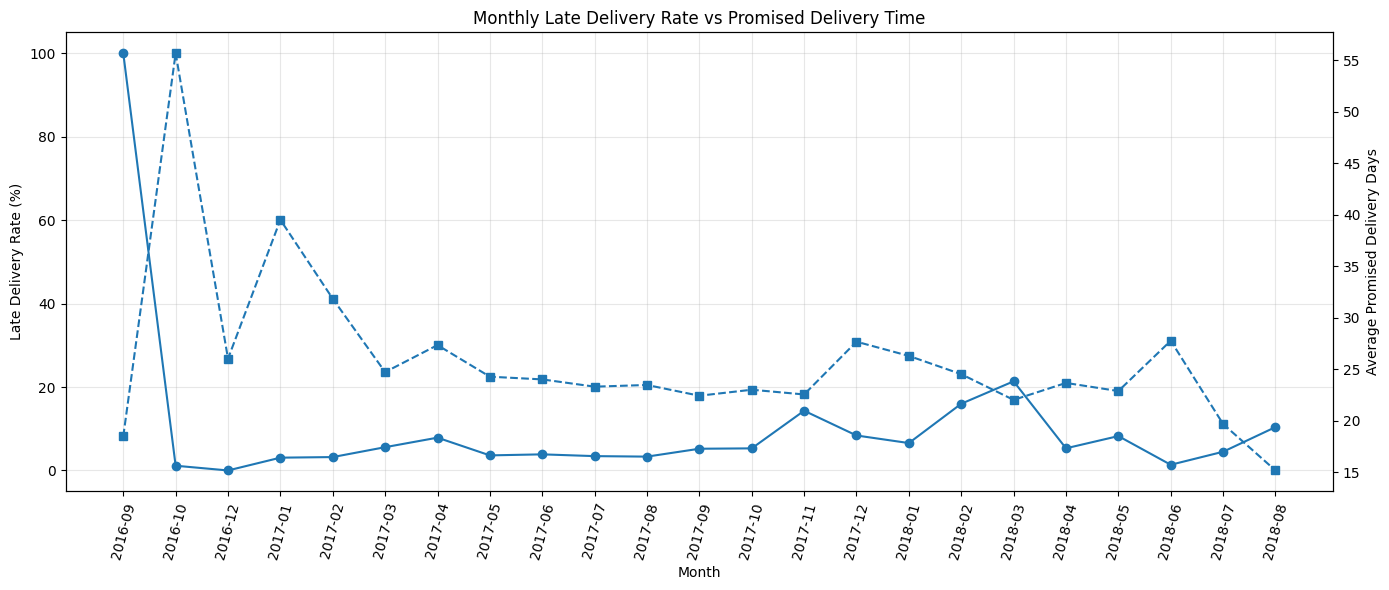

In [739]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    monthly_feature_check["month"],
    monthly_feature_check["late_rate_pct"],
    marker="o",
    label="Late Delivery Rate (%)"
)
ax1.set_ylabel("Late Delivery Rate (%)")
ax1.set_xlabel("Month")
ax1.tick_params(axis="x", rotation=75)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(
    monthly_feature_check["month"],
    monthly_feature_check["avg_promised_days"],
    marker="s",
    linestyle="--",
    label="Average Promised Days"
)
ax2.set_ylabel("Average Promised Delivery Days")

plt.title("Monthly Late Delivery Rate vs Promised Delivery Time")
fig.tight_layout()
plt.show()

In [740]:

import joblib

# Save the fitted pipeline and the validation-selected threshold
model_artifact = {
    "model": final_model,
    "threshold": final_threshold,
    "feature_columns": feature_cols,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "target": "late_delivery",
    "model_name": "Logistic Regression",
    "validation_best_f1": float(lr_best["f1"]),
    "validation_average_precision": float(
        average_precision_score(y_val, val_probabilities)
    ),
    "test_average_precision": float(
        average_precision_score(y_test, test_scores)
    ),
    "test_roc_auc": float(
        roc_auc_score(y_test, test_scores)
    ),
    "test_precision": float(
        precision_score(y_test, test_predictions, zero_division=0)
    ),
    "test_recall": float(
        recall_score(y_test, test_predictions, zero_division=0)
    ),
    "test_f1": float(
        f1_score(y_test, test_predictions, zero_division=0)
    )
}

model_path = data_dir / "late_delivery_model.joblib"

joblib.dump(model_artifact, model_path)

print("Model saved at:", model_path)
print("File exists:", model_path.exists())


Model saved at: C:\Users\KISHAN PANWAR\Downloads\archive\late_delivery_model.joblib
File exists: True


In [741]:

import shutil
from pathlib import Path

# Your actual project folder
project_dir = Path(
    r"C:\Users\KISHAN PANWAR\OneDrive\Documents\Desktop\DATASCIENCE\Projects\Olist Project"
)

# Existing saved model
source_model = data_dir / "late_delivery_model.joblib"

# Destination inside your project
project_model = project_dir / "late_delivery_model.joblib"

# Create project folder if it doesn't exist
project_dir.mkdir(parents=True, exist_ok=True)

# Copy the saved model
shutil.copy2(source_model, project_model)

print("Model copied successfully!")
print("Destination:", project_model)
print("File exists:", project_model.exists())
print("File size (KB):", round(project_model.stat().st_size / 1024, 2))


Model copied successfully!
Destination: C:\Users\KISHAN PANWAR\OneDrive\Documents\Desktop\DATASCIENCE\Projects\Olist Project\late_delivery_model.joblib
File exists: True
File size (KB): 7.49
